In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import cmocean
import cartopy.crs as ccrs

In [14]:
import healpy

In [2]:
plt.style.use("../nice.mplstyle")

In [74]:
ds2

<xarray.Dataset> Size: 9MB
Dimensions:                            (time: 57247)
Coordinates:
  * time                               (time) datetime64[ns] 458kB 2010-07-16...
    latitude                           (time) float64 458kB -61.9 ... 87.98
    longitude                          (time) float64 458kB 191.9 ... 283.3
Data variables: (12/18)
    altitude                           (time) float64 458kB ...
    range                              (time) float64 458kB ...
    wet_tropospheric_correction        (time) float64 458kB ...
    wet_tropospheric_correction_model  (time) float64 458kB ...
    dry_tropospheric_correction_model  (time) float64 458kB ...
    dynamic_atmospheric_correction     (time) float64 458kB ...
    ...                                 ...
    mean_sea_surface                   (time) float64 458kB ...
    sea_level_anomaly                  (time) float64 458kB 0.0641 ... nan
    inter_mission_bias                 (time) float64 458kB ...
    validation_flag                    (time) float32 229kB 1.0 1.0 ... 1.0 1.0
    pass_number                        (time) int32 229kB ...
    cycle_number                       (time) int32 229kB ...
Attributes: (12/25)
    Conventions:               CF-1.6
    cycle_number:              7
    pass_number:               204
    absolute_pass_number:      5244
    first_meas_time:           2010-07-16 00:04:57.358270
    last_meas_time:            2010-07-16 00:09:31.898438
    ...                        ...
    based_on:                  Cryosat-2 NTC
    creator_url:               http://aviso.altimetry.fr
    processing_level:          L2P
    software_version:          L2PDT: 5.02.0; OCTANT: 13.3.0-20200525
    product_version:           L2PNTC : 04_00
    creation_date:             2024-03-04T13:37:36

In [63]:
ds3

<xarray.Dataset> Size: 3MB
Dimensions:         (time: 40532)
Coordinates:
  * time            (time) datetime64[ns] 324kB 2010-07-16T00:22:02.874289920...
    latitude        (time) float64 324kB -56.33 -56.27 -56.22 ... -61.99 -62.04
    longitude       (time) float64 324kB 14.45 14.44 14.43 ... 203.9 203.9 203.9
Data variables:
    cycle           (time) int16 81kB ...
    track           (time) int16 81kB ...
    sla_unfiltered  (time) float64 324kB ...
    sla_filtered    (time) float64 324kB 0.032 0.038 0.044 ... -0.031 -0.036
    dac             (time) float64 324kB ...
    ocean_tide      (time) float64 324kB ...
    internal_tide   (time) float64 324kB ...
    lwe             (time) float64 324kB ...
    mdt             (time) float64 324kB ...
    tpa_correction  float64 8B ...
Attributes: (12/44)
    Conventions:                     CF-1.6
    Metadata_Conventions:            Unidata Dataset Discovery v1.0
    cdm_data_type:                   Swath
    comment:                         Sea surface height measured by altimeter...
    contact:                         servicedesk.cmems@mercator-ocean.eu
    creator_email:                   servicedesk.cmems@mercator-ocean.eu
    ...                              ...
    summary:                         SSALTO/DUACS Delayed-Time Level-3 sea su...
    time_coverage_duration:          P22H52M7.56572S
    time_coverage_end:               2010-07-16T23:14:09Z
    time_coverage_resolution:        P1S
    time_coverage_start:             2010-07-16T00:22:02Z
    title:                           DT Cryosat-2 Global Ocean Along track SS...

In [58]:
ds3 = xr.open_dataset("data/l3/dt_global_c2_phy_l3_1hz_20100716_20240205.nc")
#ds2 = xr.open_dataset("data/l2p/global_sla_l2p_ntc_c2_C0007_P0204_20100716T000457_20100716T000931_20240304T133736.nc")
ds2 = xr.open_dataset("data/l2p/dataset-l2p-uncross-calibrated-ntc-sla-c2_20100716_merged.nc")
hds25 = xr.open_dataset("data/healpix/l2p_c2_sea_level_anomaly_L5_20100716.nc")
hds35 = xr.open_dataset("data/healpix/l2p_c2_sla_filtered_L5_20100716.nc")
hds26 = xr.open_dataset("data/healpix/l2p_c2_sea_level_anomaly_L6_20100716.nc")
hds36 = xr.open_dataset("data/healpix/l2p_c2_sla_filtered_L6_20100716.nc")
hds27 = xr.open_dataset("data/healpix/l2p_c2_sea_level_anomaly_L7_20100716.nc")
hds37 = xr.open_dataset("data/healpix/l2p_c2_sla_filtered_L7_20100716.nc")
hds29 = xr.open_dataset("data/healpix/l2p_c2_sea_level_anomaly_L9_20100716.nc")
hds39 = xr.open_dataset("data/healpix/l2p_c2_sla_filtered_L9_20100716.nc")

hds25 = hds25.rename({"lon": "longitude", "lat": "latitude"})
hds35 = hds35.rename({"lon": "longitude", "lat": "latitude"})
hds26 = hds26.rename({"lon": "longitude", "lat": "latitude"})
hds36 = hds36.rename({"lon": "longitude", "lat": "latitude"})
hds27 = hds27.rename({"lon": "longitude", "lat": "latitude"})
hds37 = hds37.rename({"lon": "longitude", "lat": "latitude"})
hds29 = hds29.rename({"lon": "longitude", "lat": "latitude"})
hds39 = hds39.rename({"lon": "longitude", "lat": "latitude"})

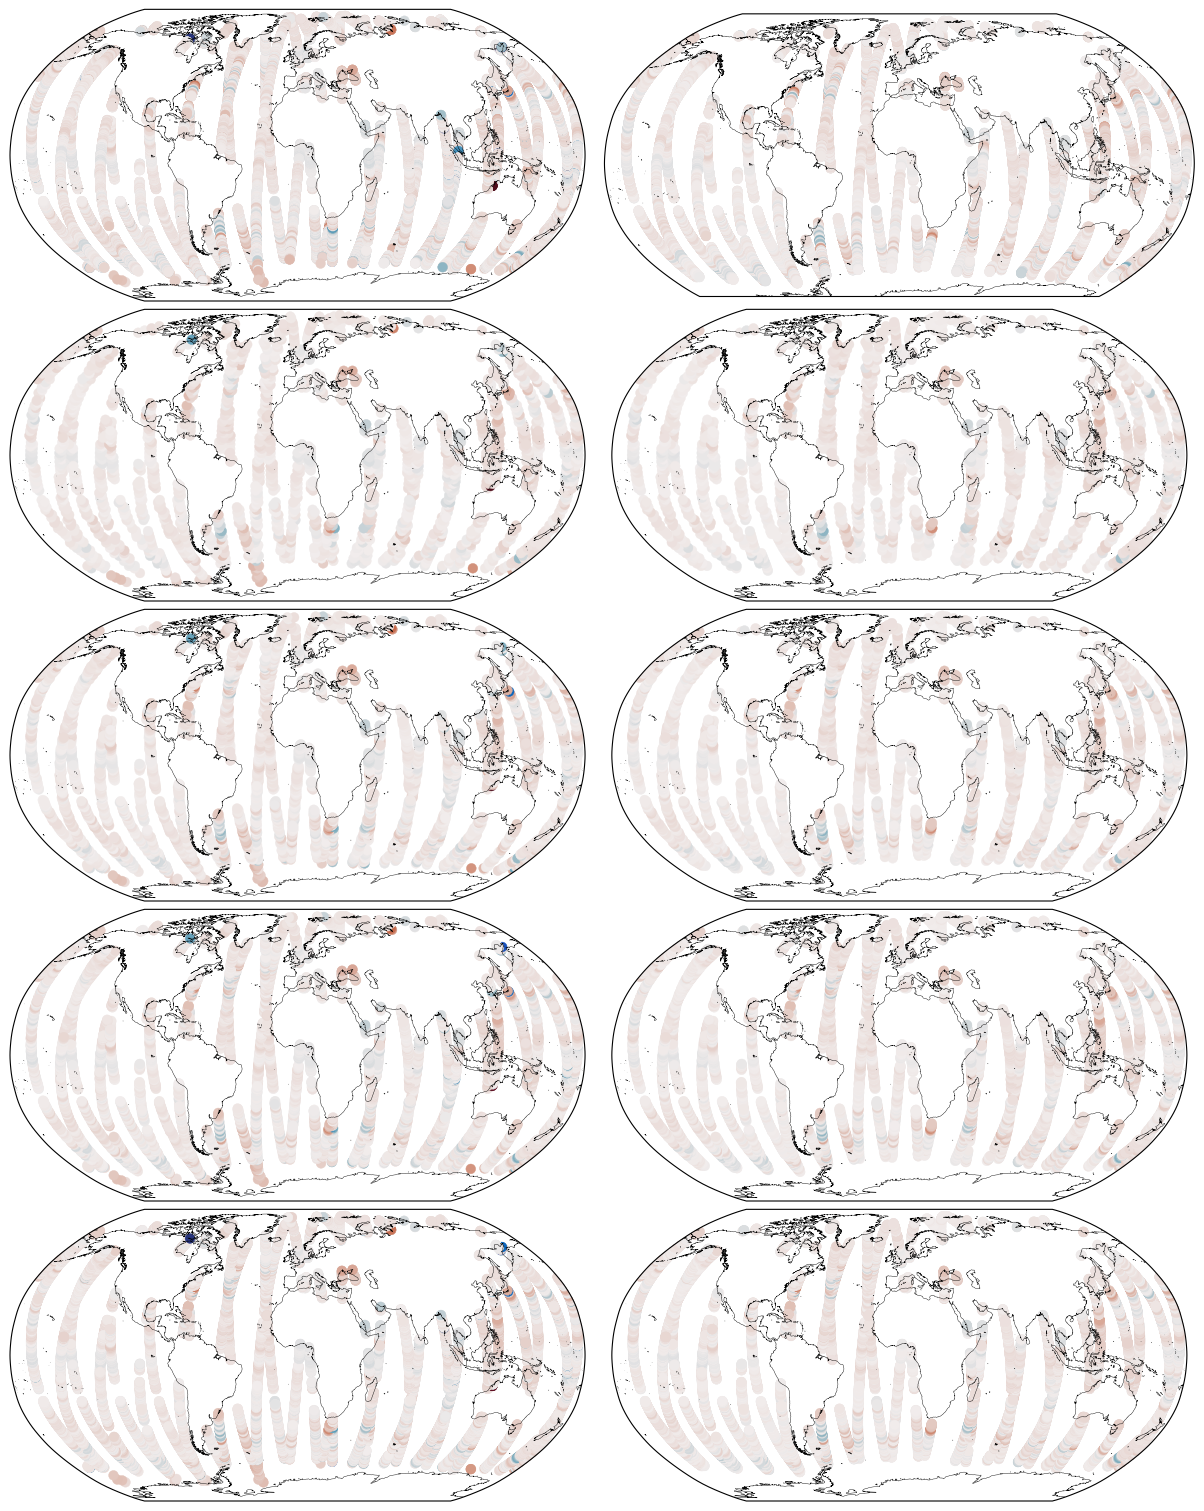

In [59]:
nrows = 5
fig, axs = plt.subplots(nrows, 2, figsize=(12,3*nrows), subplot_kw={"projection": ccrs.Robinson()})

vmax = 2

for xds, ax in zip(
    [ds2, ds3, hds25, hds35, hds26, hds36, hds27, hds37, hds29, hds39],
    axs.flatten(),
):
    varname = "sea_level_anomaly"
    varname = varname if varname in xds else "sla_filtered"
    xda = xds[varname]
    ax.scatter(
        xda.longitude,
        xda.latitude,
        c=xda,
        transform=ccrs.PlateCarree(),
        cmap="cmo.balance",
        vmin=-vmax,
        vmax=vmax,
    )
    ax.coastlines("50m")

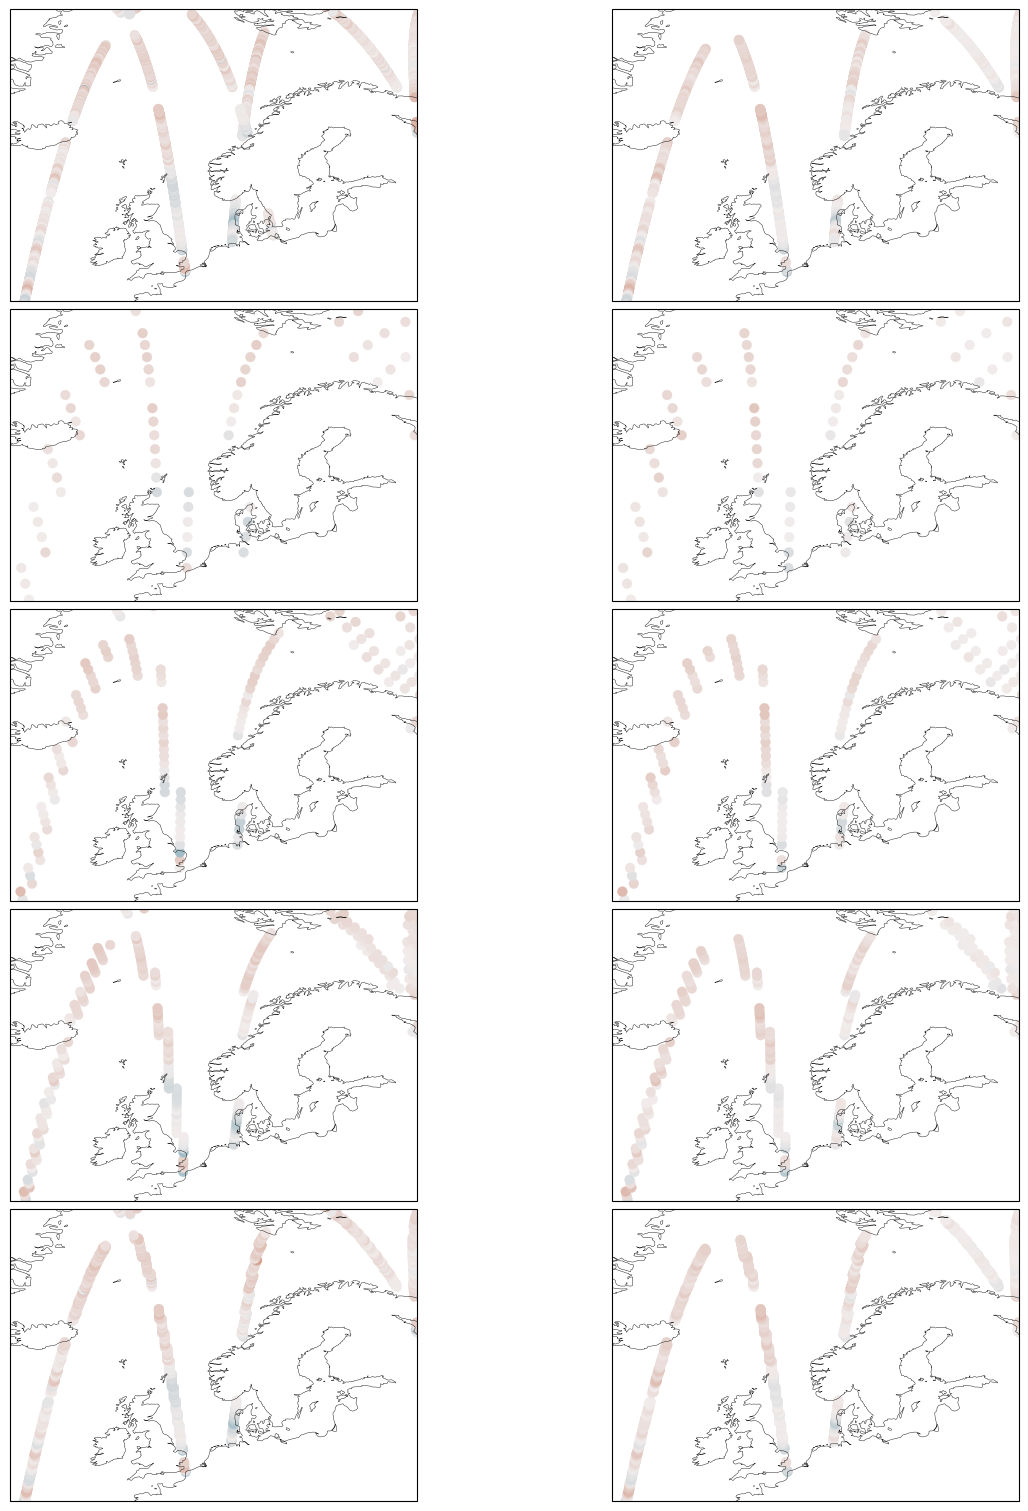

In [60]:
nrows = 5
fig, axs = plt.subplots(nrows, 2, figsize=(12,3*nrows), subplot_kw={"projection": ccrs.Robinson()})

vmax = 1

for xds, ax in zip(
    [ds2, ds3, hds25, hds35, hds26, hds36, hds27, hds37, hds29, hds39],
    axs.flatten(),
):
    varname = "sea_level_anomaly"
    varname = varname if varname in xds else "sla_filtered"
    xda = xds[varname]
    ax.scatter(
        xda.longitude,
        xda.latitude,
        c=xda,
        transform=ccrs.PlateCarree(),
        cmap="cmo.balance",
        vmin=-vmax,
        vmax=vmax,
    )
    ax.coastlines("50m")
    ax.set_extent([-20, 30, 48, 80], crs=ccrs.PlateCarree())

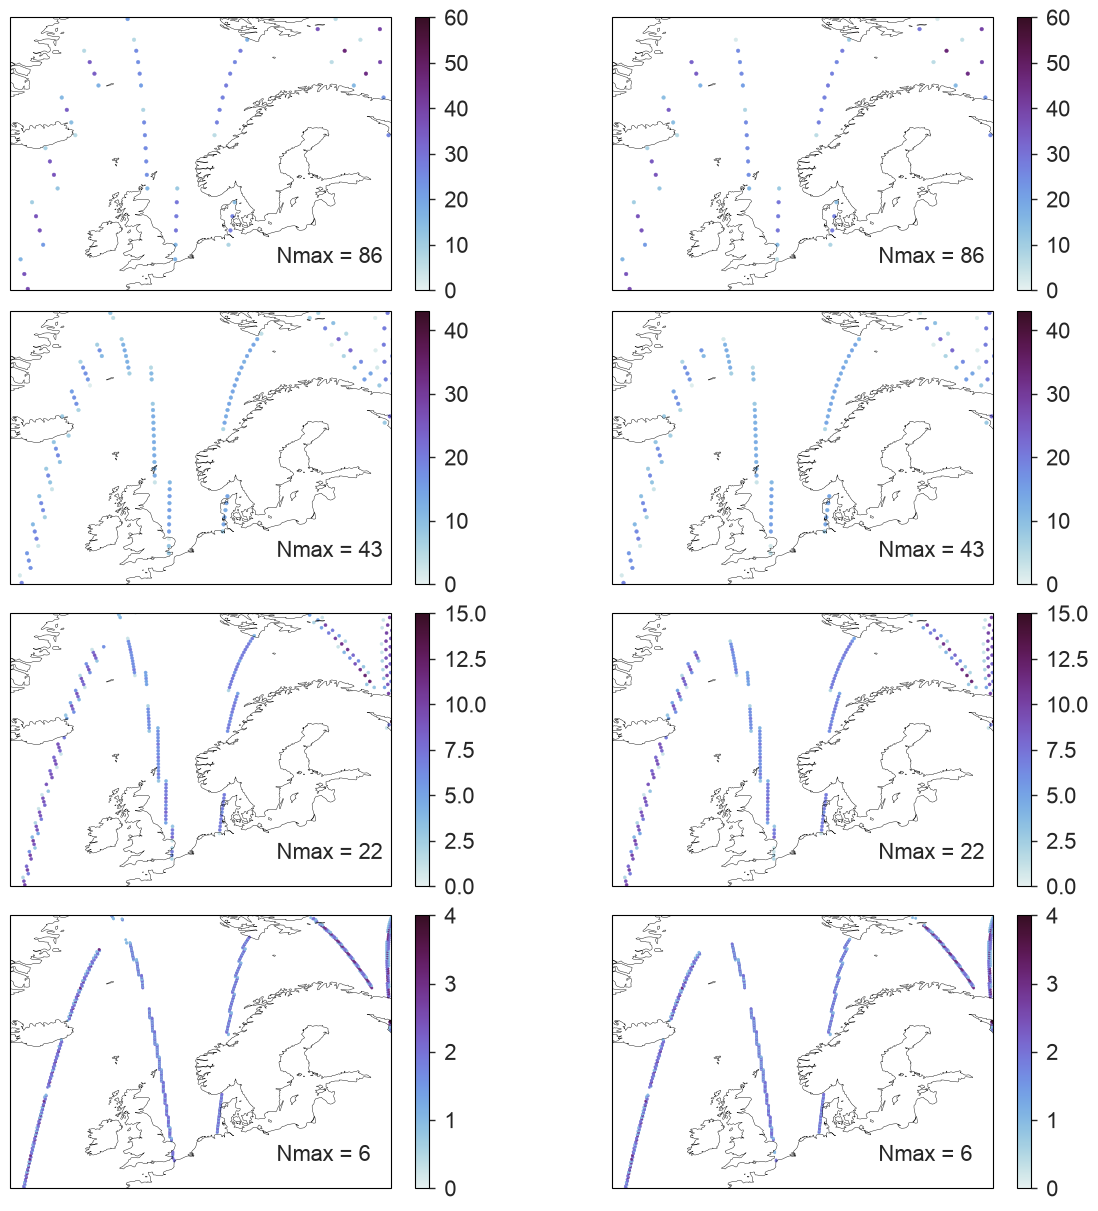

In [61]:
nrows = 4
fig, axs = plt.subplots(nrows, 2, figsize=(12,3*nrows), subplot_kw={"projection": ccrs.Robinson()})

for xds, s, vmax, ax in zip(
    [hds25, hds35, hds26, hds36, hds27, hds37, hds29, hds39],
    [7, 7, 7, 7, 5, 5, 3, 3],
    [60, 60, None, None, 15, 15, 4, 4],
    axs.flatten(),
):
    varname = "obs_count"
    xda = xds[varname]
    p = ax.scatter(
        xda.longitude,
        xda.latitude,
        c=xda.where(xda>0),
        transform=ccrs.PlateCarree(),
        cmap="cmo.dense",
        s=s,
        vmin=0,
        vmax=vmax,
    )
    plt.colorbar(p, ax=ax)
    ax.text(.7, .1, f"Nmax = {xda.max().values}", transform=ax.transAxes)
    ax.coastlines("50m")
    ax.set_extent([-20, 30, 48, 80], crs=ccrs.PlateCarree())

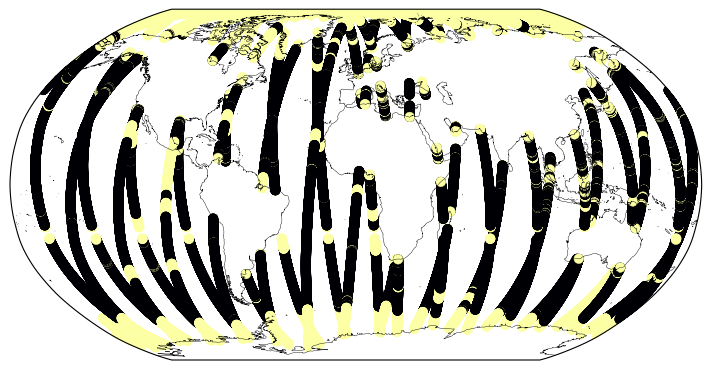

In [72]:
fig, ax = plt.subplots(subplot_kw={"projection": ccrs.Robinson()})

ax.scatter(
    ds2.longitude,
    ds2.latitude,
    c=ds2.validation_flag,
    transform=ccrs.PlateCarree()
) 
ax.coastlines("50m")

In [73]:
ds2.sea_level_anomaly.where(ds2.validation_flag == 0, drop=True)

<xarray.DataArray 'sea_level_anomaly' (time: 41357)> Size: 331kB
array([ 0.0481, -0.0301,  0.0489, ...,  0.1222,  0.1074,  0.1514],
      shape=(41357,))
Coordinates:
  * time       (time) datetime64[ns] 331kB 2010-07-16T00:22:02.874289984 ... ...
    latitude   (time) float64 331kB -56.33 -56.27 -56.22 ... 79.03 79.09 79.14
    longitude  (time) float64 331kB 14.45 14.44 14.43 ... 3.562 3.503 3.443
Attributes:
    quality_flag:   validation_flag
    comment:        altitude of satellite (altitude) - ocean altimeter range ...
    long_name:      sea level anomaly
    standard_name:  sea_surface_height_above_sea_level
    units:          m

In [ ]:
ds2